In [28]:
import numpy as np
import matplotlib.pyplot as plt

The diffusion process $X_t$ for $t\in T$ is defined to be the strong solution to
$$
\mathrm{d}X_t=b(X_t)\mathrm{d}t+\sigma(X_t)\mathrm{d}W_t
$$
for $W_t$ the usual brownian motion. A first example is $b(x)=-\theta x$ and $\sigma(x)=c\sqrt{1+x^2}$ which is ergodic if $\theta+c^2/2>0$ with stationary distribution $\pi(x)\propto(1+x^2)^{-1-\theta/c^2}$.

In [29]:
def b(x, theta = .5): return -theta * x
def s(x, c = .5): return c * (1 + (x ** 2)) ** .5

In [30]:
sigma = 1.  # Standard deviation.
mu = 10.  # Mean.
tau = .05  # Time constant.

dt = .001  # Time step.
T = 1000.  # Total time.
n = int(T / dt)  # Number of time steps.
t = np.linspace(0., T, n)  # Vector of times.

sigma_bis = sigma
sqrtdt = np.sqrt(dt)

x1 = np.ones(n) * .00001
x2 = np.ones(n) * .00001
x3 = np.ones(n) * .00001

In [31]:
# Ergodic example
for i in range(n - 1):
    x1[i + 1] = x1[i] + dt * b(x1[i]) + \
        s(x1[i], c = .5) * sigma * sqrtdt * np.random.randn()

In [32]:
# ergodic example 2
for i in range(n - 1):
    x2[i + 1] = x2[i] + dt * b(x2[i], theta = 0) + \
        s(x2[i], c = .2) * sigma * sqrtdt * np.random.randn()

In [33]:
# non ergodic example (BM)
for i in range(n - 1):
    x3[i + 1] = x3[i] + sqrtdt * np.random.randn()

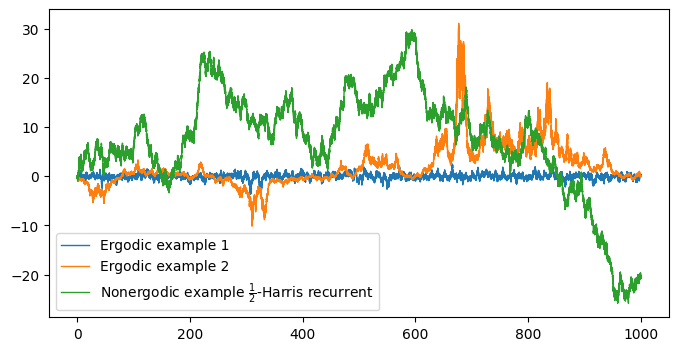

In [34]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(t, x1, lw=1, label = 'Ergodic example 1')
ax.plot(t, x2, lw=1, label = 'Ergodic example 2')
ax.plot(t, x3, lw=1, label = r'Nonergodic example $\frac{1}{2}$-Harris recurrent')
plt.legend()
plt.show()